In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [2]:
real_news = pd.read_csv("True.csv")
fake_news = pd.read_csv("Fake.csv")

In [3]:
real_news["Category"] = "Real News"
fake_news["Category"] = "Fake News"


In [4]:
news = pd.concat([real_news, fake_news], ignore_index=True)


In [5]:
news["title"] = news["title"].fillna("")
news["text"] = news["text"].fillna("")

In [6]:
news["news_text"] = news["title"] + " " + news["text"]

In [7]:
news[["Category", "news_text"]].head()

,Category,news_text
0,Real News,"As U.S. budget fight looms, Republicans flip t..."
1,Real News,U.S. military to accept transgender recruits o...
2,Real News,Senior U.S. Republican senator: 'Let Mr. Muell...
3,Real News,FBI Russia probe helped by Australian diplomat...
4,Real News,Trump wants Postal Service to charge 'much mor...


In [8]:
# sentiment scores
analyzer = SentimentIntensityAnalyzer()

news["sentiment_score"] = news["news_text"].apply(lambda text: analyzer.polarity_scores(text)["compound"])

news["sentiment_intensity"] = news["sentiment_score"].abs()

news[["Category", "sentiment_score", "sentiment_intensity"]].head()

,Category,sentiment_score,sentiment_intensity
0,Real News,0.9831,0.9831
1,Real News,-0.3941,0.3941
2,Real News,-0.6808,0.6808
3,Real News,-0.2201,0.2201
4,Real News,0.7157,0.7157


In [9]:
# count words in each article
news["word_count"] = news["news_text"].str.findall(
    r"\b[a-zA-Z]+\b"
).str.len()

news[["Category", "word_count"]].head()

,Category,word_count
0,Real News,758
1,Real News,641
2,Real News,475
3,Real News,396
4,Real News,858


In [10]:
# separate words
words = news["news_text"].str.lower().str.findall(
    r"\b[a-z]+\b"
).explode()

words.head(10)

0             as
0              u
0              s
0         budget
0          fight
0          looms
0    republicans
0           flip
0          their
0         fiscal
Name: news_text, dtype: object

In [11]:
# Identify emotionally charged words
word_scores = words.map(analyzer.lexicon)

emotional_word_count = (word_scores.abs().ge(2.0).groupby(level=0).sum())

news["emotional_word_count"] = emotional_word_count

news[["Category", "emotional_word_count"]].head()

,Category,emotional_word_count
0,Real News,3
1,Real News,13
2,Real News,4
3,Real News,6
4,Real News,5


In [12]:
# emotional-word percentage
news["emotional_word_percentage"] = (news["emotional_word_count"]/ news["word_count"].replace(0, 1) * 100)

news[["Category", "word_count","emotional_word_count", "emotional_word_percentage"]].head()

,Category,word_count,emotional_word_count,emotional_word_percentage
0,Real News,758,3,0.395778
1,Real News,641,13,2.028081
2,Real News,475,4,0.842105
3,Real News,396,6,1.515152
4,Real News,858,5,0.582751


In [13]:
# classify writing style
news["Writing_Style"] = "Neutral"

news.loc[
    (news["emotional_word_percentage"] >= 5) |
    (news["sentiment_intensity"] >= 0.3),
    "Writing_Style"
] = "Emotionally Charged"

news[["Category", "sentiment_intensity","emotional_word_percentage", "Writing_Style"]].head()

,Category,sentiment_intensity,emotional_word_percentage,Writing_Style
0,Real News,0.9831,0.395778,Emotionally Charged
1,Real News,0.3941,2.028081,Emotionally Charged
2,Real News,0.6808,0.842105,Emotionally Charged
3,Real News,0.2201,1.515152,Neutral
4,Real News,0.7157,0.582751,Emotionally Charged


In [14]:
# count writing styles by category
style_count = pd.crosstab(news["Category"],news["Writing_Style"])

style_count

Writing_Style,Emotionally Charged,Neutral
Category,,
Fake News,22173,1308
Real News,19482,1935


In [15]:
# writing style percentage
style_percentage = pd.crosstab(news["Category"],news["Writing_Style"],normalize="index") * 100

style_percentage.round(2)

Writing_Style,Emotionally Charged,Neutral
Category,,
Fake News,94.43,5.57
Real News,90.97,9.03


In [16]:
# compare potential bias indicators
bias_comparison = news.groupby("Category").agg(
    Average_Sentiment_Intensity=("sentiment_intensity", "mean"),
    Average_Emotional_Word_Percentage=("emotional_word_percentage", "mean")
)

bias_comparison.round(3)

,Average_Sentiment_Intensity,Average_Emotional_Word_Percentage
Category,,
Fake News,0.83,2.932
Real News,0.79,1.912


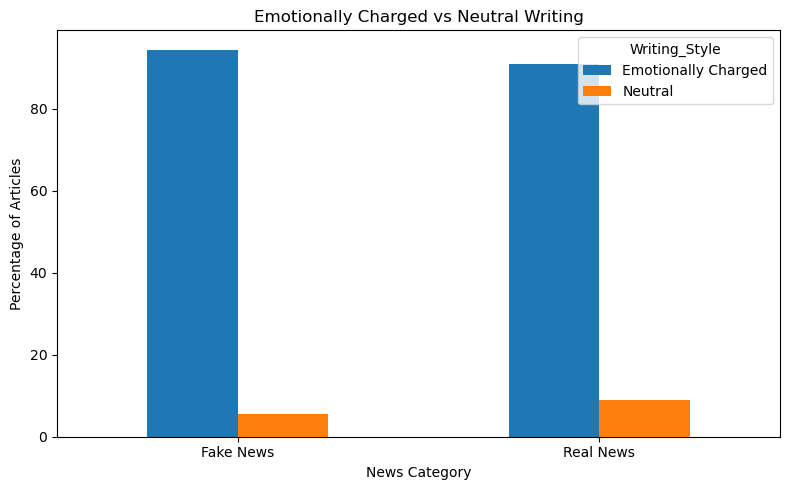

In [17]:
style_percentage.plot(kind="bar", figsize=(8, 5))

plt.title("Emotionally Charged vs Neutral Writing")
plt.xlabel("News Category")
plt.ylabel("Percentage of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()